# 18 - Extending to the top 5 leagues

Research before touching the pipeline: does the model hold up outside the
Premier League, and should the five leagues share **one pooled model** or
get **one model each**?

- **Data** - football-data.co.uk results + odds and Understat xG for the
  Premier League, La Liga, Bundesliga, Serie A and Ligue 1, 21-22 onwards.
  Downloaded once and cached under `data/raw/top5/` (re-run with
  `REFRESH_CURRENT = True` to pick up new 26-27 results).
- **Features** - the deployed three (`EloDiff`, `XGDDiffLast5`,
  `GoalsPerGameDiff`) plus Dixon-Coles, built **separately per league**
  with the exact functions the pipeline uses.
- **Evaluation** - the same walk-forward backtest as notebooks 16/17:
  train on seasons before, test 22-23 to 25-26, pool. Log loss first,
  accuracy and flat-stake profit alongside.

Team names stay in football-data's spelling throughout; Understat names are
matched to them automatically (by date + score), so nothing needs adding to
`team_names.csv` yet.

In [1]:
import sys
sys.path.append("../src")

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import penaltyblog as pb

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, log_loss

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from fetch_results import _download_csv
from load_data import add_gameweek
from predict_next_matches import (
    build_elo_feature,
    build_goals_per_game_feature,
    build_xgd_last5_feature,
)
from dixon_coles import build_dixon_coles_feature, DC_FEATURES

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)

## Download and cache

In [2]:
LEAGUES = {
    "E0": {"name": "Premier League", "understat": "ENG Premier League"},
    "SP1": {"name": "La Liga", "understat": "ESP La Liga"},
    "D1": {"name": "Bundesliga", "understat": "DEU Bundesliga 1"},
    "I1": {"name": "Serie A", "understat": "ITA Serie A"},
    "F1": {"name": "Ligue 1", "understat": "FRA Ligue 1"},
}
LEAGUE_NAMES = {code: league["name"] for code, league in LEAGUES.items()}

SEASONS = ["21-22", "22-23", "23-24", "24-25", "25-26", "26-27"]
CURRENT_SEASON = SEASONS[-1]
REFRESH_CURRENT = False  # True re-downloads 26-27 (finished seasons never change)

CACHE_DIR = Path("../data/raw/top5")

# Only what this notebook needs from football-data's ~200 columns
RESULT_COLUMNS = [
    "Div", "Date", "Time", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR",
    "PSCH", "PSCD", "PSCA", "AvgCH", "AvgCD", "AvgCA", "AvgH", "AvgD", "AvgA",
]
UNDERSTAT_KEEP = ["date", "team_home", "team_away", "goals_home", "goals_away", "xg_home", "xg_away"]


def cached(path, fetch, refresh=False):
    """Read ``path`` if it exists, otherwise ``fetch()`` and save it there."""
    if path.exists() and not refresh:
        return pd.read_csv(path)
    frame = fetch()
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=False)
    return frame


def football_data_url(code, season):
    return f"https://www.football-data.co.uk/mmz4281/{season.replace('-', '')}/{code}.csv"


def understat_season(season):
    start, end = season.split("-")
    return f"20{start}-20{end}"


results, understat = [], []

for code, league in LEAGUES.items():
    for season in SEASONS:

        refresh = REFRESH_CURRENT and season == CURRENT_SEASON

        frame = cached(
            CACHE_DIR / code / f"{season}.csv",
            lambda: _download_csv(football_data_url(code, season)).reindex(columns=RESULT_COLUMNS),
            refresh,
        )
        results.append(frame.assign(Season=season))

        frame = cached(
            CACHE_DIR / code / f"understat_{season}.csv",
            lambda: pb.scrapers.Understat(league["understat"], understat_season(season))
                      .get_fixtures()[UNDERSTAT_KEEP],
            refresh,
        )
        understat.append(frame.assign(Season=season, Div=code))

results = pd.concat(results, ignore_index=True).dropna(subset=["FTR"])
understat = pd.concat(understat, ignore_index=True).dropna(subset=["xg_home", "xg_away"])

results.groupby(["Div", "Season"]).size().unstack()

Season,21-22,22-23,23-24,24-25,25-26,26-27
Div,,,,,,
D1,306,306,306,306,306,54
E0,380,380,380,380,380,70
F1,380,380,306,306,306,63
I1,380,380,380,380,380,70
SP1,380,380,380,380,380,89


## Matching Understat team names to football-data's

"Ath Bilbao" vs "Athletic Club", "Ein Frankfurt" vs "Eintracht Frankfurt"...
Rather than typing ~100 aliases, match each league's fixtures across the two
sources on date (+/- 1 day, since Understat is in UTC) and exact score, then
let every matched fixture vote on which names belong together. The real
pairing gets dozens of votes per season; coincidental same-day same-score
matches get a handful, and the greedy one-to-one assignment discards them.

In [3]:
def match_team_names(fd, us):
    """Understat name -> football-data name for one league, by fixture voting."""

    fd = fd.assign(day=pd.to_datetime(fd["Date"], dayfirst=True))
    us = us.assign(day=pd.to_datetime(us["date"]).dt.normalize())

    candidates = pd.concat([
        fd.merge(
            us.assign(day=us["day"] + pd.Timedelta(days=shift)),
            left_on=["day", "FTHG", "FTAG"], right_on=["day", "goals_home", "goals_away"],
        )
        for shift in (-1, 0, 1)
    ])

    votes = pd.concat([
        candidates[["team_home", "HomeTeam"]].set_axis(["understat", "football_data"], axis=1),
        candidates[["team_away", "AwayTeam"]].set_axis(["understat", "football_data"], axis=1),
    ]).value_counts().reset_index()

    # Greedy one-to-one: strongest pairing first, each name used once
    mapping = {}
    for _, row in votes.iterrows():
        if row["understat"] not in mapping and row["football_data"] not in mapping.values():
            mapping[row["understat"]] = row["football_data"]

    return mapping, votes


name_maps, name_checks = {}, []

for code in LEAGUES:
    mapping, votes = match_team_names(results[results["Div"] == code], understat[understat["Div"] == code])
    name_maps[code] = mapping

    for us_name, fd_name in mapping.items():
        pair_votes = votes[(votes["understat"] == us_name) & (votes["football_data"] == fd_name)]["count"].iloc[0]
        name_checks.append({"Div": code, "Understat": us_name, "football-data": fd_name, "Votes": pair_votes})

name_checks = pd.DataFrame(name_checks)

# Every team on both sides must be mapped exactly once
for code in LEAGUES:
    fd_teams = set(results.loc[results["Div"] == code, ["HomeTeam", "AwayTeam"]].stack())
    us_teams = set(understat.loc[understat["Div"] == code, ["team_home", "team_away"]].stack())
    assert set(name_maps[code]) == us_teams, code
    assert set(name_maps[code].values()) == fd_teams, code

print("Weakest pairings (should still be well clear of chance):")
name_checks.sort_values("Votes").head(10)

Weakest pairings (should still be well clear of chance):


,Div,Understat,football-data,Votes
83,D1,Elversberg,Elversberg,6
84,D1,Paderborn,Paderborn,6
27,E0,Hull,Hull,7
28,E0,Coventry,Coventry,7
137,F1,Le Mans,Le Mans,7
55,SP1,Racing Santander,Santander,9
57,SP1,Malaga,Malaga,9
56,SP1,Deportivo La Coruna,La Coruna,9
81,D1,Darmstadt,Darmstadt,34
80,D1,Greuther Fuerth,Greuther Furth,34


In [4]:
# The pairings where the spellings actually differ - eyeball these
name_checks[name_checks["Understat"] != name_checks["football-data"]].sort_values(["Div", "football-data"])

,Div,Understat,football-data,Votes
79,D1,Arminia Bielefeld,Bielefeld,34
61,D1,Borussia Dortmund,Dortmund,176
64,D1,Eintracht Frankfurt,Ein Frankfurt,176
71,D1,FC Cologne,FC Koln,142
80,D1,Greuther Fuerth,Greuther Furth,34
78,D1,Hamburger SV,Hamburg,40
74,D1,FC Heidenheim,Heidenheim,102
76,D1,Hertha Berlin,Hertha,68
66,D1,Bayer Leverkusen,Leverkusen,176
58,D1,Borussia M.Gladbach,M'gladbach,176


In [5]:
understat["HomeTeam"] = [name_maps[d][t] for d, t in zip(understat["Div"], understat["team_home"])]
understat["AwayTeam"] = [name_maps[d][t] for d, t in zip(understat["Div"], understat["team_away"])]

xg = (
    understat.rename(columns={"xg_home": "HomeXG", "xg_away": "AwayXG"})
    .drop_duplicates(subset=["Div", "Season", "HomeTeam", "AwayTeam"])
    [["Div", "Season", "HomeTeam", "AwayTeam", "HomeXG", "AwayXG"]]
)

matches = results.merge(xg, on=["Div", "Season", "HomeTeam", "AwayTeam"], how="left")
matches["MatchDateTime"] = pd.to_datetime(matches["Date"] + " " + matches["Time"], dayfirst=True)

print("xG coverage by league and season:")
matches.assign(has_xg=matches["HomeXG"].notna()).pivot_table(
    index="Div", columns="Season", values="has_xg", aggfunc="mean"
).rename(index=LEAGUE_NAMES)

xG coverage by league and season:


Season,21-22,22-23,23-24,24-25,25-26,26-27
Div,,,,,,
Bundesliga,1.0,1.0,1.0,1.0,1.0,1.0000
Premier League,1.0,1.0,1.0,1.0,1.0,1.0000
Ligue 1,1.0,1.0,1.0,1.0,1.0,0.9841
Serie A,1.0,1.0,1.0,1.0,1.0,1.0000
La Liga,1.0,1.0,1.0,1.0,1.0,1.0000


## Features, built per league

Elo, form, goals per game and Dixon-Coles each only see a league's own
matches - teams from different leagues never meet, so mixing them would
make no sense. The Elo settings (home advantage 130, K = 35) were tuned on
the Premier League and are reused unchanged.

In [6]:
original_features = ["EloDiff", "XGDDiffLast5", "GoalsPerGameDiff"]

leagues = []

for code in LEAGUES:   # ~15-20s per league, mostly the Dixon-Coles refits
    league = add_gameweek(matches[matches["Div"] == code])
    build_elo_feature(league)
    build_goals_per_game_feature(league)
    build_xgd_last5_feature(league)
    build_dixon_coles_feature(league)
    leagues.append(league)

data = (
    pd.concat(leagues, ignore_index=True)
    .sort_values(["MatchDateTime", "Div", "HomeTeam"])
    .reset_index(drop=True)
)

# League indicators for the pooled model (Premier League is the baseline)
LEAGUE_COLUMNS = [f"League_{code}" for code in LEAGUES if code != "E0"]
for code in LEAGUES:
    if code != "E0":
        data[f"League_{code}"] = (data["Div"] == code).astype(int)

LABELS = ["A", "D", "H"]
data["y"] = data["FTR"].map({label: i for i, label in enumerate(LABELS)})

data.groupby("Div").size().rename(index=LEAGUE_NAMES)

Div
Bundesliga        1584
Premier League    1970
Ligue 1           1741
Serie A           1970
La Liga           1989
dtype: int64

## How different are the leagues?

If home advantage and draw rates differ a lot between leagues, a pooled
model needs league indicators to absorb that.

In [7]:
profile = data.groupby("Div").agg(
    Matches=("FTR", "size"),
    HomeWin=("FTR", lambda r: (r == "H").mean()),
    Draw=("FTR", lambda r: (r == "D").mean()),
    AwayWin=("FTR", lambda r: (r == "A").mean()),
    GoalsPerGame=("FTHG", lambda g: (g + data.loc[g.index, "FTAG"]).mean()),
    EloDiffSpread=("EloDiff", "std"),
).rename(index=LEAGUE_NAMES)
profile

,Matches,HomeWin,Draw,AwayWin,GoalsPerGame,EloDiffSpread
Div,,,,,,
Bundesliga,1584,0.4432,0.2475,0.3093,3.1932,146.5001
Premier League,1970,0.4401,0.2406,0.3193,2.9259,159.9950
Ligue 1,1741,0.4348,0.2453,0.3199,2.8294,147.0927
Serie A,1970,0.4061,0.2685,0.3254,2.6178,159.9233
La Liga,1989,0.4565,0.2624,0.2810,2.6164,150.5798


## Bookmaker benchmark and metrics

Same as notebook 17: Pinnacle closing odds (market-average closing odds
where missing), margin removed. Profit is a 1-unit flat stake on each
pick at the **market-average opening odds** - the same fallback
`backtest.py` and `fetch_results.py` use.

In [8]:
test_seasons = ["22-23", "23-24", "24-25", "25-26"]
test = data[data["Season"].isin(test_seasons)]
y_test = test["y"].to_numpy()
div_test = test["Div"].to_numpy()
season_test = test["Season"].to_numpy()


def implied_probabilities(frame):
    odds = frame[["PSCA", "PSCD", "PSCH"]].to_numpy(dtype=float)
    fallback = frame[["AvgCA", "AvgCD", "AvgCH"]].to_numpy(dtype=float)
    odds = np.where(np.isnan(odds), fallback, odds)
    raw = 1 / odds
    return raw / raw.sum(axis=1, keepdims=True)


bookmaker_proba = implied_probabilities(test)
assert not np.isnan(bookmaker_proba).any()

pick_odds = test[["AvgA", "AvgD", "AvgH"]].to_numpy(dtype=float)


def per_match_log_loss(y_true, proba):
    return -np.log(np.clip(proba[np.arange(len(y_true)), y_true], 1e-15, 1))


def flat_stake_profit(y_true, proba, odds):
    pick = proba.argmax(axis=1)
    won = pick == y_true
    return np.where(won, odds[np.arange(len(pick)), pick] - 1, -1.0)


def score(y_true, proba, odds):
    profit = flat_stake_profit(y_true, proba, odds)
    return {
        "LogLoss": log_loss(y_true, proba, labels=[0, 1, 2]),
        "Accuracy": accuracy_score(y_true, proba.argmax(axis=1)),
        "Profit": profit.sum(),
        "ROI": profit.mean(),
    }

## The models

All built on the same walk-forward loop. `per_league=True` trains a
separate model on each league's own history (what you'd get by simply
running today's pipeline five times); otherwise one model is trained on
every league's history together.

In [9]:
def walk_forward(make_model, features, per_league=False):
    """Out-of-sample probabilities for every test match, in ``test`` order."""

    predictions = []

    for season in test_seasons:

        train_all = data[data["Season"] < season]
        test_all = data[data["Season"] == season]

        if per_league:
            groups = [
                (train_all[train_all["Div"] == code], test_all[test_all["Div"] == code])
                for code in LEAGUES
            ]
        else:
            groups = [(train_all, test_all)]

        for train, held_out in groups:
            model = make_model().fit(train[features], train["y"])
            predictions.append(
                pd.DataFrame(model.predict_proba(held_out[features]), index=held_out.index)
            )

    return pd.concat(predictions).loc[test.index].to_numpy()


calibrated = lambda clf: CalibratedClassifierCV(estimator=clf, method="sigmoid", cv=5)

deployed_lr = lambda: calibrated(LogisticRegression(max_iter=2000, random_state=42))
strong_l2_lr = lambda: calibrated(make_pipeline(
    StandardScaler(), LogisticRegression(C=0.05, max_iter=2000, random_state=42)
))

tree_models = {
    "Random forest": lambda: calibrated(RandomForestClassifier(
        n_estimators=500, max_depth=6, min_samples_leaf=20, max_features="sqrt",
        n_jobs=-1, random_state=42,
    )),
    "Extra trees": lambda: calibrated(ExtraTreesClassifier(
        n_estimators=500, max_depth=6, min_samples_leaf=20, max_features="sqrt",
        n_jobs=-1, random_state=42,
    )),
    "HistGradientBoosting": lambda: calibrated(HistGradientBoostingClassifier(
        learning_rate=0.03, max_iter=200, max_depth=3, min_samples_leaf=40,
        l2_regularization=1.0, random_state=42,
    )),
    "XGBoost": lambda: calibrated(XGBClassifier(
        n_estimators=300, learning_rate=0.02, max_depth=2, min_child_weight=10,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0,
        objective="multi:softprob", eval_metric="mlogloss", n_jobs=-1, random_state=42,
    )),
    "LightGBM": lambda: calibrated(LGBMClassifier(
        n_estimators=300, learning_rate=0.02, num_leaves=4, min_child_samples=40,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0,
        n_jobs=-1, random_state=42, verbose=-1,
    )),
}

with_dc = original_features + DC_FEATURES

In [10]:
# ~5-10 minutes
configs = {
    # name: (model factory, features, per_league)
    "Per-league LR (today's model x5)": (deployed_lr, original_features, True),
    "Per-league LR + DC": (strong_l2_lr, with_dc, True),
    "Pooled LR": (deployed_lr, original_features, False),
    "Pooled LR + league": (deployed_lr, original_features + LEAGUE_COLUMNS, False),
    "Pooled LR + league + DC": (strong_l2_lr, with_dc + LEAGUE_COLUMNS, False),
}
for name, factory in tree_models.items():
    configs[f"Pooled {name} + league"] = (factory, original_features + LEAGUE_COLUMNS, False)
    configs[f"Pooled {name} + league + DC"] = (factory, with_dc + LEAGUE_COLUMNS, False)

probas = {name: walk_forward(*config) for name, config in configs.items()}

# Base rates: each league's own H/D/A frequencies from the training seasons
base_rate_proba = np.zeros((len(test), 3))
for season in test_seasons:
    for code in LEAGUES:
        train = data[(data["Season"] < season) & (data["Div"] == code)]
        rates = train["y"].value_counts(normalize=True).reindex([0, 1, 2]).to_numpy()
        base_rate_proba[(season_test == season) & (div_test == code)] = rates

probas["Base rates (per league)"] = base_rate_proba
probas["Bookmaker (Pinnacle close)"] = bookmaker_proba

## Results - all five leagues pooled

In [11]:
reference = "Per-league LR (today's model x5)"
reference_losses = per_match_log_loss(y_test, probas[reference])

rng = np.random.default_rng(42)
boot_index = rng.integers(0, len(y_test), size=(5000, len(y_test)))

overall = []
for name, proba in probas.items():
    diff = per_match_log_loss(y_test, proba) - reference_losses
    boot = diff[boot_index].mean(axis=1)
    overall.append({
        "Model": name,
        **score(y_test, proba, pick_odds),
        "Diff vs per-league LR": diff.mean(),
        "95% CI low": np.percentile(boot, 2.5),
        "95% CI high": np.percentile(boot, 97.5),
    })

overall = pd.DataFrame(overall).sort_values("LogLoss").reset_index(drop=True)
print(f"{len(y_test):,} test matches across 5 leagues, 22-23 to 25-26")
overall

7,082 test matches across 5 leagues, 22-23 to 25-26


,Model,LogLoss,Accuracy,Profit,ROI,Diff vs per-league LR,95% CI low,95% CI high
0,Bookmaker (Pinnacle close),0.9666,0.5446,-7.36,-0.0010,-2.5142e-02,-0.0297,-2.0287e-02
1,Pooled Extra trees + league + DC,0.9873,0.5281,-213.11,-0.0301,-4.4532e-03,-0.0081,-8.2813e-04
2,Pooled LR + league + DC,0.9888,0.5258,-223.71,-0.0316,-2.9522e-03,-0.0052,-7.1068e-04
3,Pooled LR + league,0.9889,0.5288,-138.67,-0.0196,-2.8148e-03,-0.0044,-1.2279e-03
4,Pooled LR,0.9891,0.5287,-152.31,-0.0215,-2.6399e-03,-0.0047,-5.4061e-04
5,Pooled XGBoost + league + DC,0.9893,0.5273,-219.29,-0.0310,-2.3872e-03,-0.0056,8.3974e-04
6,Pooled Random forest + league + DC,0.9895,0.5265,-243.76,-0.0344,-2.2603e-03,-0.0058,1.2374e-03
7,Pooled Extra trees + league,0.9898,0.5271,-168.31,-0.0238,-1.9422e-03,-0.0038,-5.4260e-05
8,Pooled LightGBM + league + DC,0.9902,0.5254,-252.51,-0.0357,-1.5148e-03,-0.0046,1.5832e-03
9,Per-league LR (today's model x5),0.9917,0.5260,-193.59,-0.0273,0.0000e+00,0.0000,0.0000e+00


### Do the tree models now beat logistic regression?

With ~5x the data, the trees get a second chance. Same paired bootstrap,
but against the pooled logistic regression with league indicators.

In [12]:
challenger_reference = "Pooled LR + league"
challenger_losses = per_match_log_loss(y_test, probas[challenger_reference])

challengers = []
for name in overall["Model"].head(8):
    if name in (challenger_reference, "Bookmaker (Pinnacle close)"):
        continue
    diff = per_match_log_loss(y_test, probas[name]) - challenger_losses
    boot = diff[boot_index].mean(axis=1)
    challengers.append({
        "Model": name,
        "Diff vs pooled LR + league": diff.mean(),
        "95% CI low": np.percentile(boot, 2.5),
        "95% CI high": np.percentile(boot, 97.5),
        f"P(better)": (boot < 0).mean(),
        "Seasons better": sum(
            log_loss(y_test[season_test == s], probas[name][season_test == s], labels=[0, 1, 2])
            < log_loss(y_test[season_test == s], probas[challenger_reference][season_test == s], labels=[0, 1, 2])
            for s in test_seasons
        ),
    })

pd.DataFrame(challengers)

,Model,Diff vs pooled LR + league,95% CI low,95% CI high,P(better),Seasons better
0,Pooled Extra trees + league + DC,-0.0016,-0.0052,0.0018,0.8302,2
1,Pooled LR + league + DC,-0.0001,-0.0019,0.0016,0.5626,2
2,Pooled LR,0.0002,-0.0010,0.0014,0.3848,1
3,Pooled XGBoost + league + DC,0.0004,-0.0025,0.0034,0.3806,1
4,Pooled Random forest + league + DC,0.0006,-0.0027,0.0038,0.3632,1
5,Pooled Extra trees + league,0.0009,-0.0008,0.0026,0.1558,1


## Results by league

In [13]:
headline = [
    "Base rates (per league)",
    "Per-league LR (today's model x5)",
    "Pooled LR",
    "Pooled LR + league",
    "Pooled LR + league + DC",
    "Bookmaker (Pinnacle close)",
]
best_tree = overall[overall["Model"].str.contains("forest|trees|Boost|LightGBM")].iloc[0]["Model"]
headline.insert(-1, best_tree)

by_league = {}
for metric in ["LogLoss", "Accuracy", "ROI"]:
    by_league[metric] = pd.DataFrame({
        name: {
            LEAGUE_NAMES[code]: score(y_test[div_test == code], probas[name][div_test == code],
                                      pick_odds[div_test == code])[metric]
            for code in LEAGUES
        }
        for name in headline
    })

print("Log loss by league (lower is better)")
by_league["LogLoss"]

Log loss by league (lower is better)


,Base rates (per league),Per-league LR (today's model x5),Pooled LR,Pooled LR + league,Pooled LR + league + DC,Pooled Extra trees + league + DC,Bookmaker (Pinnacle close)
Premier League,1.0689,0.9805,0.9791,0.9802,0.9832,0.9833,0.9605
La Liga,1.0639,0.9907,0.9872,0.9847,0.9813,0.9762,0.9595
Bundesliga,1.0749,0.9985,0.9935,0.9939,0.9932,0.9909,0.9697
Serie A,1.0869,0.9937,0.9913,0.9914,0.9919,0.9891,0.9670
Ligue 1,1.0706,0.9973,0.9963,0.9964,0.9962,0.9992,0.9784


In [14]:
print("Accuracy by league")
by_league["Accuracy"]

Accuracy by league


,Base rates (per league),Per-league LR (today's model x5),Pooled LR,Pooled LR + league,Pooled LR + league + DC,Pooled Extra trees + league + DC,Bookmaker (Pinnacle close)
Premier League,0.4447,0.5434,0.5395,0.5434,0.5349,0.5329,0.5454
La Liga,0.4632,0.5204,0.5322,0.5329,0.5296,0.5355,0.5500
Bundesliga,0.4338,0.5196,0.5163,0.5147,0.5163,0.5237,0.5498
Serie A,0.4072,0.5276,0.5283,0.5303,0.5289,0.5243,0.5395
Ligue 1,0.4368,0.5162,0.5239,0.5185,0.5162,0.5223,0.5385


In [15]:
print("Return per 1-unit flat bet on every pick, at market-average opening odds")
by_league["ROI"]

Return per 1-unit flat bet on every pick, at market-average opening odds


,Base rates (per league),Per-league LR (today's model x5),Pooled LR,Pooled LR + league,Pooled LR + league + DC,Pooled Extra trees + league + DC,Bookmaker (Pinnacle close)
Premier League,-0.0576,-0.0053,-0.0134,-0.0016,-0.0292,-0.0377,-0.0274
La Liga,-0.0270,-0.0216,0.0067,0.0086,-0.0054,0.0089,0.0327
Bundesliga,-0.1059,-0.0549,-0.0615,-0.0684,-0.0665,-0.0531,0.0033
Serie A,-0.1344,-0.0168,-0.0215,-0.0097,-0.0171,-0.0351,-0.0057
Ligue 1,-0.0751,-0.0462,-0.0263,-0.0391,-0.0490,-0.0391,-0.0083


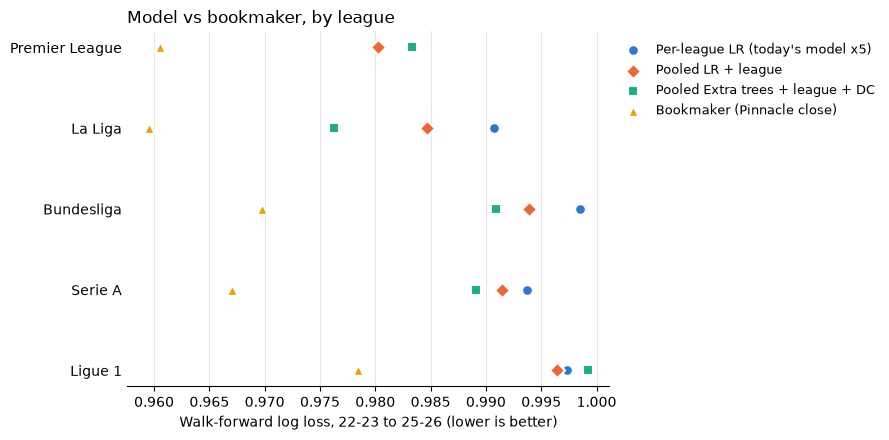

In [16]:
# Log loss by league: today's model run per league vs the pooled model vs the bookmaker
series = {
    "Per-league LR (today's model x5)": ("#2a78d6", "o"),
    "Pooled LR + league": ("#eb6834", "D"),
    best_tree: ("#1baf7a", "s"),
    "Bookmaker (Pinnacle close)": ("#eda100", "^"),
}

table = by_league["LogLoss"]
fig, ax = plt.subplots(figsize=(9, 4.5))
y_pos = np.arange(len(table))[::-1]

for name, (color, marker) in series.items():
    ax.scatter(table[name], y_pos, s=60, color=color, marker=marker,
               edgecolor="white", linewidth=1.5, label=name, zorder=3)

ax.set_yticks(y_pos)
ax.set_yticklabels(table.index)
ax.set_xlabel("Walk-forward log loss, 22-23 to 25-26 (lower is better)")
ax.set_title("Model vs bookmaker, by league", loc="left")
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1), fontsize=9)
plt.tight_layout()
plt.show()

## Does pooling help every league, or just on average?

Paired bootstrap per league: pooled-with-league-indicators vs today's model
trained per league. Negative = pooling is better.

In [17]:
pooled_name = "Pooled LR + league"
league_significance = []

for code in LEAGUES:
    mask = div_test == code
    diff = (per_match_log_loss(y_test[mask], probas[pooled_name][mask])
            - per_match_log_loss(y_test[mask], probas[reference][mask]))
    idx = rng.integers(0, mask.sum(), size=(5000, mask.sum()))
    boot = diff[idx].mean(axis=1)
    league_significance.append({
        "League": LEAGUE_NAMES[code],
        "Diff (pooled - per-league)": diff.mean(),
        "95% CI low": np.percentile(boot, 2.5),
        "95% CI high": np.percentile(boot, 97.5),
        "P(pooled better)": (boot < 0).mean(),
        "Seasons pooled wins": sum(
            log_loss(y_test[mask & (season_test == s)], probas[pooled_name][mask & (season_test == s)], labels=[0, 1, 2])
            < log_loss(y_test[mask & (season_test == s)], probas[reference][mask & (season_test == s)], labels=[0, 1, 2])
            for s in test_seasons
        ),
    })

pd.DataFrame(league_significance)

,League,Diff (pooled - per-league),95% CI low,95% CI high,P(pooled better),Seasons pooled wins
0,Premier League,-0.0002,-0.0034,0.0029,0.5594,2
1,La Liga,-0.0061,-0.0104,-0.0020,0.9980,2
2,Bundesliga,-0.0046,-0.0093,0.0002,0.9684,4
3,Serie A,-0.0023,-0.0051,0.0005,0.9440,4
4,Ligue 1,-0.0009,-0.0036,0.0018,0.7554,4


## What the pooled model learned

Coefficients of the pooled logistic regression (+ league indicators),
fitted on every completed season. The league columns are shifts relative to
the Premier League - i.e. how much more or less likely a home win / away
win / draw is in that league once the team-strength features are equal.

In [18]:
final_features = original_features + LEAGUE_COLUMNS
completed = data[data["Season"] != CURRENT_SEASON]
coef_model = LogisticRegression(max_iter=2000, random_state=42).fit(completed[final_features], completed["y"])

pd.DataFrame(coef_model.coef_.T, index=final_features, columns=[f"-> {label}" for label in LABELS])

,-> A,-> D,-> H
EloDiff,-0.0025,5.4014e-05,0.0024
XGDDiffLast5,-0.1056,-5.4519e-02,0.1602
GoalsPerGameDiff,-0.0965,4.3327e-02,0.0532
League_SP1,-0.1278,7.4730e-02,0.0531
League_D1,-0.0270,2.7368e-02,-0.0003
League_I1,0.0147,1.0777e-01,-0.1225
League_F1,0.0196,8.7673e-03,-0.0284


## Season by season

Pooled log loss (all leagues) per test season, for the leading setups.

In [19]:
season_names = list(overall["Model"].head(6)) + [reference, "Bookmaker (Pinnacle close)"]
season_names = list(dict.fromkeys(season_names))

pd.DataFrame({
    name: {
        season: log_loss(y_test[season_test == season], probas[name][season_test == season], labels=[0, 1, 2])
        for season in test_seasons
    }
    for name in season_names
}).T

,22-23,23-24,24-25,25-26
Bookmaker (Pinnacle close),0.9749,0.9525,0.9606,0.9780
Pooled Extra trees + league + DC,0.9963,0.9769,0.9851,0.9905
Pooled LR + league + DC,0.9966,0.9781,0.9856,0.9945
Pooled LR + league,0.9930,0.9768,0.9858,0.9999
Pooled LR,0.9935,0.9772,0.9848,1.0007
Pooled XGBoost + league + DC,1.0001,0.9788,0.9858,0.9921
Per-league LR (today's model x5),0.9965,0.9813,0.9870,1.0019


## Conclusion

**1. The model works outside the Premier League.** On all 7,082 test
matches it beats each league's base rates by 0.07-0.09 log loss, and the
gap to the bookmaker is a similar ~0.02 in every league:

| League | Base rates | Today's model, per league | Pooled LR + league | Bookmaker |
|---|---|---|---|---|
| Premier League | 1.0689 | 0.9805 | 0.9802 | 0.9605 |
| La Liga | 1.0639 | 0.9907 | 0.9847 | 0.9595 |
| Bundesliga | 1.0749 | 0.9985 | 0.9939 | 0.9697 |
| Serie A | 1.0869 | 0.9937 | 0.9914 | 0.9670 |
| Ligue 1 | 1.0706 | 0.9973 | 0.9964 | 0.9784 |

**2. Pool the leagues into one model.** One logistic regression trained on
all five leagues beats running today's model separately per league: 0.9889
vs 0.9917 overall (95% CI -0.0044 to -0.0012, clear of zero). It helps
every non-Premier League league (significantly in La Liga; the Bundesliga,
Serie A and Ligue 1 improve in all 4 seasons), and leaves the Premier
League unchanged. An Elo gap or xG gap means about the same thing in any
league, so the smaller leagues borrow strength from the rest.

**3. League indicators: keep them, but they're minor.** They barely change
log loss (0.9889 vs 0.9891), but the coefficients make sense - Serie A has
more draws, La Liga fewer away wins - and they cost nothing.

**4. Trees still don't clearly win, even with ~5x the data.** Extra trees
+ Dixon-Coles has the best raw number (0.9873), but against pooled logistic
regression the interval includes zero (-0.0052 to +0.0018) and it's better
in only 2 of 4 seasons. XGBoost, random forest and LightGBM are level or
worse. Dixon-Coles adds nothing to the pooled logistic regression
(-0.0001).

**5. Nothing here makes money at average odds.** Flat-staking every pick
at market-average opening odds loses in every setup: about -2.0% ROI for
the pooled model and -2.7% for today's model per league. Even backing the
bookmaker's own favourite is about break-even (-0.1%), because the average
bookmaker margin is roughly what an edge would need to overcome. The
Premier League is closest to break-even; the Bundesliga is worst.

**6. The data side is solved.** Matching Understat team names to
football-data names by date and score mapped every team in all five
leagues one-to-one. The lowest-vote pairings are 26-27 promoted sides with
identical spellings, and xG coverage is 100% (one 26-27 Ligue 1 match
pending).

**Recommendation for the pipeline:** one pooled, calibrated logistic
regression on the three current features plus four league indicators,
with Elo, form and goals per game still built per league. `name_checks`
above lists the team-name pairings needed for `team_names.csv`.
